# Transfer Learning: 17 Kinds of Flowers from 40 Photos Each

This notebook goes with the lecture on transfer learning. In Lecture 14 our CNN learned CIFAR-10 from 45,000 training photos and reached about 63% on the test photos. A final project rarely has 45,000 labeled photos. Here we have **40 photos per class**, and the question is how far that gets us:

1. trained **from scratch**, the way we have trained every network so far;
2. with a network **pretrained on ImageNet** (1.2 million photos, 1,000 classes), used as a fixed feature extractor;
3. with the same pretrained network, **fine-tuned** on our photos.

The network is **ResNet-18** from `torchvision.models`, the one on the lecture's code slides. The data is the **Oxford 17 Category Flower Dataset** (Nilsback and Zisserman, 2006): 17 kinds of flowers common in the UK, 80 photos each. The code below downloads it (60 MB) into `data/flowers17/` the first time, and the pretrained weights (45 MB) into PyTorch's cache.

Running time: about 1 minute with a GPU, about 15 minutes on a laptop CPU (most of it in the from-scratch training). Every training run is seeded, but the numbers still change a little from one computer to another (a point or so of accuracy).

In [1]:
import tarfile
import time
import urllib.request
from pathlib import Path

import cv2 as cv
import numpy as np
import scipy.io
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib import pyplot as plt
from PIL import Image
from torchvision import models, transforms

# A GPU if there is one: NVIDIA (cuda), Apple silicon (mps), otherwise the CPU
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print('device:', device)

device: cuda


## The Data: Oxford 17 Category Flowers

The archive holds 1,360 photos, `image_0001.jpg` to `image_1360.jpg`, sorted by class: the first 80 are daffodils, the next 80 snowdrops, and so on. So the label of photo number *n* is (*n* − 1) // 80, and there is no label file.

The authors also published three random **splits** of the photos into training, validation and test sets (`datasplits.mat`), so that everyone reports results on the same test photos. We use split 1: 40 training, 20 validation and 20 test photos per class, 680, 340 and 340 in all. The numbers in the file count from 1 (MATLAB), so we subtract 1.

In [2]:
root = Path('data/flowers17')
base_url = 'https://www.robots.ox.ac.uk/~vgg/data/flowers/17/'
root.mkdir(parents=True, exist_ok=True)
for name in ('17flowers.tgz', 'datasplits.mat'):
    if not (root / name).exists():
        print('downloading', name)
        urllib.request.urlretrieve(base_url + name, root / name)
if not (root / 'jpg').exists():
    with tarfile.open(root / '17flowers.tgz') as archive:
        archive.extractall(root)

files = sorted((root / 'jpg').glob('image_*.jpg'))
labels = torch.arange(len(files)) // 80
classes = ['daffodil', 'snowdrop', 'lily of the valley', 'bluebell', 'crocus', 'iris', 'tiger lily', 'tulip', 'fritillary',
           'sunflower', 'daisy', "colt's foot", 'dandelion', 'cowslip', 'buttercup', 'windflower', 'pansy']

splits = scipy.io.loadmat(root / 'datasplits.mat')
train_idx = torch.tensor(splits['trn1'].ravel() - 1, dtype=torch.long)
val_idx = torch.tensor(splits['val1'].ravel() - 1, dtype=torch.long)
test_idx = torch.tensor(splits['tst1'].ravel() - 1, dtype=torch.long)
print(len(files), 'photos,', len(classes), 'classes')
print('train', len(train_idx), ' validation', len(val_idx), ' test', len(test_idx))
print('training photos per class:', torch.bincount(labels[train_idx]).tolist())

1360 photos, 17 classes
train 680  validation 340  test 340
training photos per class: [40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40, 40]


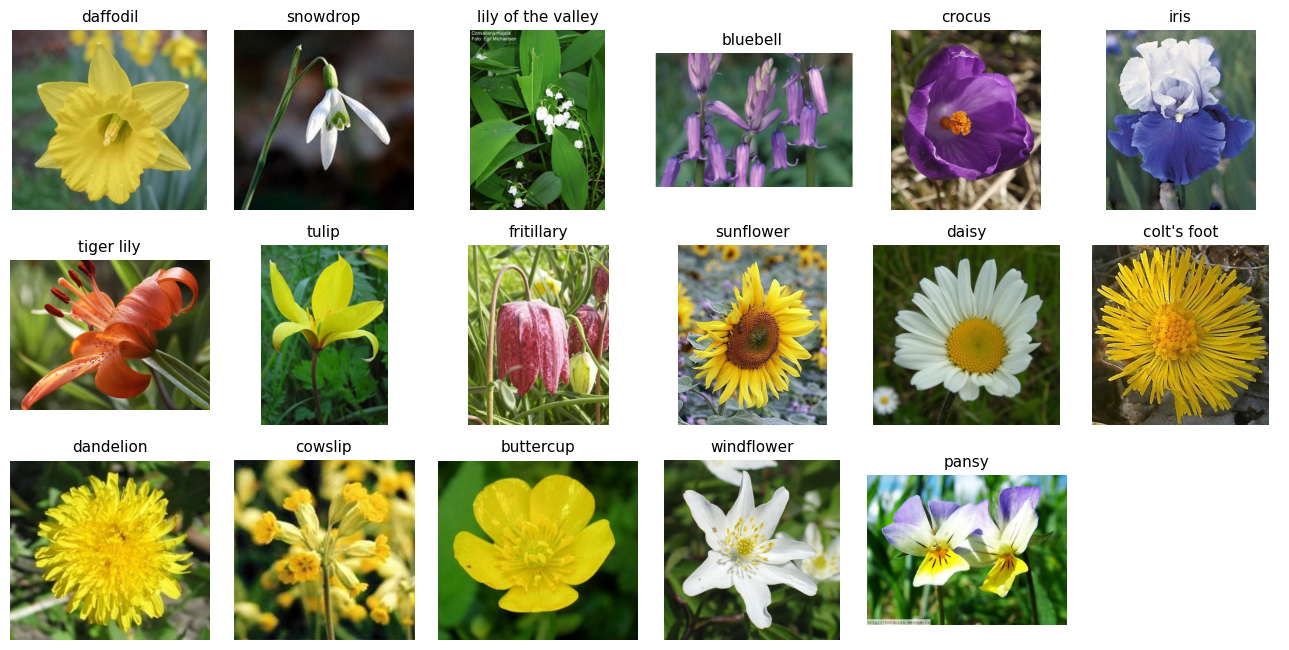

In [3]:
fig, axs = plt.subplots(3, 6, figsize=(13, 6.6))
for c, ax in enumerate(axs.flat):
    if c < len(classes):
        photo = Image.open(files[train_idx[labels[train_idx] == c][0]])
        ax.imshow(photo)
        ax.set_title(classes[c], fontsize=11)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Preparing Photos the Way the Pretrained Network Expects

A pretrained network has only ever seen photos prepared one particular way, and it must get ours prepared the same way. Since `torchvision` 0.13 the recipe comes with the weights: `weights.transforms()`. For ResNet-18 it resizes the shorter side to 256 pixels, cuts out the center 224 × 224, scales the values to 0 to 1, and **normalizes** every channel with the mean and standard deviation of the ImageNet photos.

In [4]:
weights = models.ResNet18_Weights.DEFAULT
print(weights)
print(weights.transforms())

ResNet18_Weights.IMAGENET1K_V1
ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


The resize and the crop give the same result every time, so we do them once for all 1,360 photos and keep the crops as `uint8` (200 MB, against 800 MB as floats). The last two steps happen on every batch, in `prepare()`. PIL opens a JPEG as **RGB**, the channel order ImageNet networks are trained with; remember that `cv.imread` would give BGR. A later section measures what that mistake costs.

In [5]:
resize_crop = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.PILToTensor()])
start = time.time()
images = torch.stack([resize_crop(Image.open(f).convert('RGB')) for f in files])    # (1360, 3, 224, 224), uint8
print(images.shape, images.dtype, f'({time.time() - start:.0f} s)')

mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def prepare(batch_uint8):
    """uint8 crops -> float, 0 to 1, normalized with the ImageNet mean and std, on the device."""
    x = batch_uint8.float() / 255
    return ((x - mean) / std).to(device)

torch.Size([1360, 3, 224, 224]) torch.uint8 (5 s)


## What Does the ImageNet Network Say About a Flower?

Before changing anything, ask the pretrained ResNet-18 what it sees. Its last layer, `fc`, gives 1,000 scores, one per ImageNet class, and ImageNet has almost no flower classes (`daisy` is one of the few). The network's answers are informed guesses from the wrong list of classes. We need a new last layer that answers with **our** 17 classes.

last layer: Linear(in_features=512, out_features=1000, bias=True)


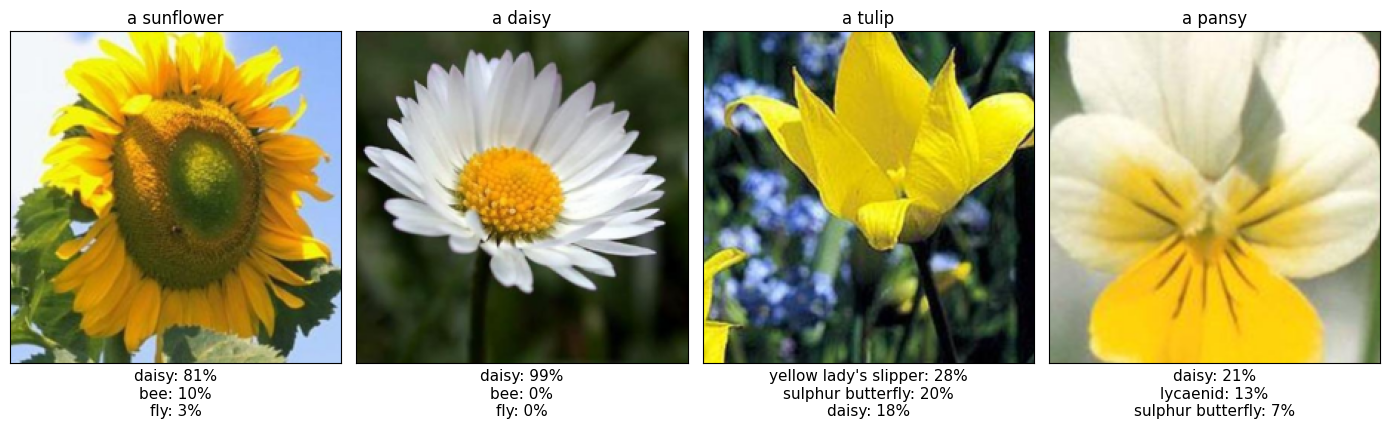

In [6]:
imagenet_net = models.resnet18(weights=weights).to(device).eval()
print('last layer:', imagenet_net.fc)
categories = weights.meta['categories']

examples = [test_idx[labels[test_idx] == c][0].item() for c in (9, 10, 7, 16)]    # sunflower, daisy, tulip, pansy
with torch.no_grad():
    probs = F.softmax(imagenet_net(prepare(images[examples])), dim=1).cpu()
fig, axs = plt.subplots(1, 4, figsize=(14, 4))
for ax, i, p in zip(axs, examples, probs):
    top = p.topk(3)
    ax.imshow(images[i].permute(1, 2, 0))
    ax.set_title(f'a {classes[labels[i]]}', fontsize=12)
    ax.set_xlabel('\n'.join(f'{categories[k]}: {v:.0%}' for v, k in zip(top.values, top.indices)), fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

## The Training Loop

One function trains every network in this notebook. It is Lecture 14's loop with three additions:

- `params` says which parameters the optimizer may change. Feature extraction passes only the new head; fine-tuning passes more.
- `augment=True` flips a random half of each batch left to right (a flipped flower is still the same flower), as in Lecture 14's data augmentation.
- `frozen_bn=True` keeps the network in `eval()` mode while training. Its `BatchNorm` layers keep running averages of what they see, which `model.train()` would update even for layers whose weights are frozen. Feature extraction should leave the pretrained network exactly as it is.

In [7]:
def accuracy(model, idx, batch=100):
    model.eval()
    correct = 0
    with torch.no_grad():
        for i in range(0, len(idx), batch):
            b = idx[i:i + batch]
            correct += (model(prepare(images[b])).argmax(1).cpu() == labels[b]).sum().item()
    return correct / len(idx)


def train(model, params, idx, epochs, lr, augment=True, frozen_bn=False, batch=32, seed=0):
    optimizer = torch.optim.Adam(params, lr=lr)
    generator = torch.Generator().manual_seed(seed)
    for epoch in range(epochs):
        start = time.time()
        model.eval() if frozen_bn else model.train()
        order = idx[torch.randperm(len(idx), generator=generator)]
        total = 0.0
        for i in range(0, len(order), batch):
            b = order[i:i + batch]
            x = prepare(images[b])
            if augment:
                flip = (torch.rand(len(b), generator=generator) < 0.5).to(device)
                x = torch.where(flip.view(-1, 1, 1, 1), x.flip(3), x)
            loss = F.cross_entropy(model(x), labels[b].to(device))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(b)
        print(f'epoch {epoch + 1:2d}  loss {total / len(idx):.3f}  validation accuracy {accuracy(model, val_idx):.1%}  ({time.time() - start:.0f} s)')


def trainable(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## Training from Scratch: The Baseline

First the way we have trained every network so far: the ResNet-18 architecture with **random** weights (`weights=None`), and a last layer with 17 outputs. All 11 million parameters have to be learned from our 680 photos.

Ten epochs take a few minutes on a CPU. That is already twice as long as the fine-tuning below gets, and the validation accuracy is still climbing, unevenly. Training from scratch on so few photos is also unstable: rerun this cell, or run it on another computer, and the test accuracy can move by ten points (on the dataset's three splits it gave 52% to 61%). Trained for 60 epochs on a GPU, the same network ends a little under 80% right (the lecture's results slide), still far behind every pretrained version below.

In [8]:
torch.manual_seed(0)
scratch = models.resnet18(weights=None, num_classes=len(classes)).to(device)
print(f'trainable parameters: {trainable(scratch):,d}')
start = time.time()
train(scratch, scratch.parameters(), train_idx, epochs=10, lr=1e-3)
print(f'RESULT scratch_test: {accuracy(scratch, test_idx):.4f}')
print(f'RESULT scratch_seconds: {time.time() - start:.0f}')

trainable parameters: 11,185,233


epoch  1  loss 2.394  validation accuracy 20.6%  (3 s)


epoch  2  loss 1.840  validation accuracy 32.9%  (3 s)


epoch  3  loss 1.769  validation accuracy 32.9%  (3 s)


epoch  4  loss 1.714  validation accuracy 35.3%  (3 s)


epoch  5  loss 1.519  validation accuracy 42.6%  (3 s)


... (2 outputs left out)

epoch  8  loss 1.256  validation accuracy 46.2%  (3 s)


epoch  9  loss 1.194  validation accuracy 51.5%  (3 s)


epoch 10  loss 1.122  validation accuracy 51.5%  (3 s)


RESULT scratch_test: 0.5441
RESULT scratch_seconds: 31


## A Pretrained Network Is a Feature Descriptor

Take the pretrained ResNet-18 and replace its last layer with `nn.Identity()`, a layer that passes its input through unchanged. What comes out is no longer 1,000 class scores but the **512 numbers** the last layer was reading: one vector per photo, like the HOG and moment descriptors of Lectures 8 and 12, except that nobody designed it by hand. The network learned it from 1.2 million ImageNet photos.

The pretrained layers are not trained here, so each photo's vector never changes: we compute all 1,360 of them once.

In [9]:
extractor = models.resnet18(weights=weights)
extractor.fc = nn.Identity()
extractor = extractor.to(device).eval()

start = time.time()
with torch.no_grad():
    features = torch.cat([extractor(prepare(images[i:i + 100])).cpu() for i in range(0, len(images), 100)])
print('features:', tuple(features.shape), f'({time.time() - start:.0f} s)')
print('photo 0, first 8 numbers:', features[0, :8].numpy().round(2))

features: (1360, 512) (2 s)
photo 0, first 8 numbers: [0.67 0.35 0.38 2.21 1.05 1.54 0.34 0.3 ]


### Nearest Neighbors: Pixels Against Features

Lecture 12 recognized faces with a 1-nearest-neighbor classifier on raw pixels: a test photo gets the label of the most similar training photo. Do the same here twice, once with the pixels of a 32 × 32 thumbnail (3,072 numbers) and once with the 512 pretrained features. Nothing is trained in either case.

In [10]:
from sklearn.neighbors import KNeighborsClassifier

pixels = F.interpolate(images.float(), size=32, mode='area').flatten(1) / 255     # (1360, 3072)
for name, X in (('pixels (32 x 32 x 3)', pixels), ('pretrained features (512)', features)):
    knn = KNeighborsClassifier(n_neighbors=1).fit(X[train_idx], labels[train_idx])
    acc = (knn.predict(X[test_idx]) == labels[test_idx].numpy()).mean()
    print(f'1-nearest neighbor on {name}: {acc:.1%}')
    print(f'RESULT knn_{name.split()[0]}: {acc:.4f}')

1-nearest neighbor on pixels (32 x 32 x 3): 37.6%
RESULT knn_pixels: 0.3765
1-nearest neighbor on pretrained features (512): 85.6%
RESULT knn_pretrained: 0.8559


Show one test photo, a buttercup, and its four nearest training photos in each space. The pixel neighbors share the color and the layout: yellow, round, in the middle. The feature neighbors share the flower.

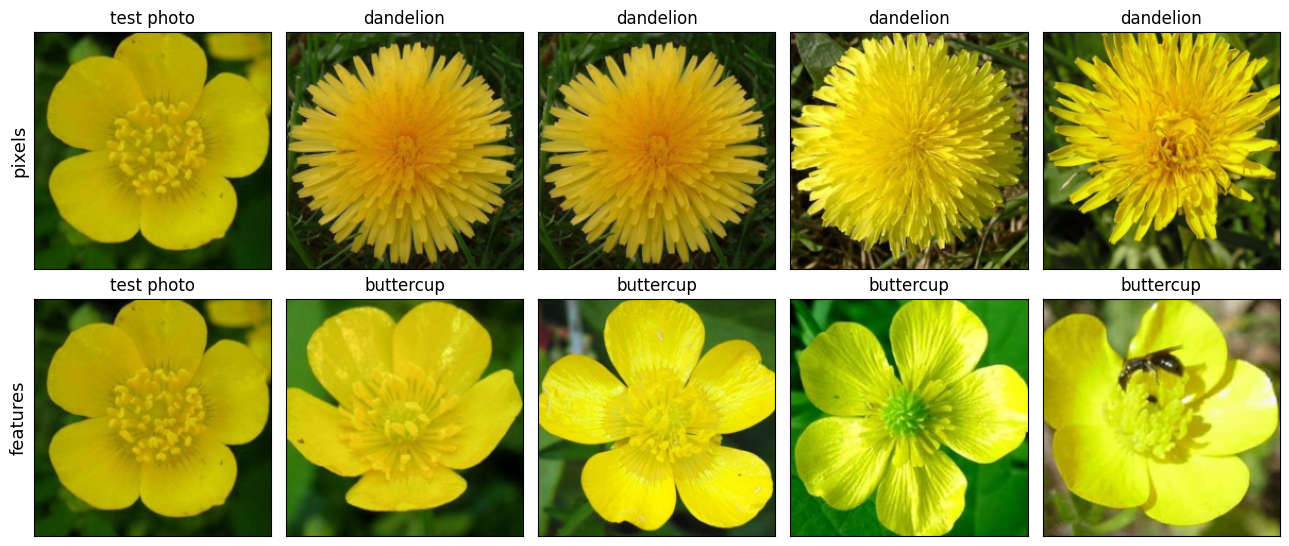

In [11]:
query = 1123                       # image_1124.jpg, a buttercup from the test set
fig, axs = plt.subplots(2, 5, figsize=(13, 5.6))
for row, (name, X) in enumerate((('pixels', pixels), ('features', features))):
    d = torch.cdist(X[query:query + 1], X[train_idx])[0]
    nearest = train_idx[d.argsort()[:4]]
    axs[row, 0].imshow(images[query].permute(1, 2, 0)); axs[row, 0].set_title('test photo')
    axs[row, 0].set_ylabel(name, fontsize=13)
    for ax, j in zip(axs[row, 1:], nearest):
        ax.imshow(images[j].permute(1, 2, 0)); ax.set_title(classes[labels[j]])
for ax in axs.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

### A Warning About This Dataset: Duplicate Photos

Some photos appear in the dataset twice, and the official split sometimes puts one copy in the training set and the other in the test set. For such a test photo, the nearest training photo is itself, and even the pixel classifier gets it right. Count them: a test photo whose closest training thumbnail differs by less than 2% of the value range, on average per pixel, is a copy.

In [12]:
distance = torch.cdist(pixels[test_idx], pixels[train_idx]).min(1).values / np.sqrt(pixels.shape[1])
twin = distance < 0.02
print(f'{int(twin.sum())} of {len(test_idx)} test photos have a copy in the training set')
print(f'RESULT duplicates: {int(twin.sum())}')
for name, X in (('pixels', pixels), ('features', features)):
    knn = KNeighborsClassifier(n_neighbors=1).fit(X[train_idx], labels[train_idx])
    right = knn.predict(X[test_idx]) == labels[test_idx].numpy()
    print(f'1-NN on {name:8s}: {right.mean():.1%} of all test photos, {right[~twin.numpy()].mean():.1%} without the copies')

21 of 340 test photos have a copy in the training set
RESULT duplicates: 21
1-NN on pixels  : 37.6% of all test photos, 33.5% without the copies
1-NN on features: 85.6% of all test photos, 84.6% without the copies


The copies flatter the pixel classifier most, but they change no conclusion. The lesson is the one your final project's rules spell out: a test set must contain nothing the model has trained on, or its score measures memory instead of recognition. Below we keep the official split so that our numbers stay comparable with other people's.

### Seeing It in 2-D

PCA (Lecture 11) projects each vector onto the two directions of greatest variance. Five classes, three of them with yellow centers, plotted in both spaces. In pixel space all five lie on top of each other. In feature space the bluebells and the tiger lilies form clusters of their own, and the three yellow-centered flowers sit close together but in different regions; two dimensions are not enough to pull them apart, the full 512 are, as the classifier below shows. A linear classifier on the features has an easy job, which is why a single new `nn.Linear` layer is enough.

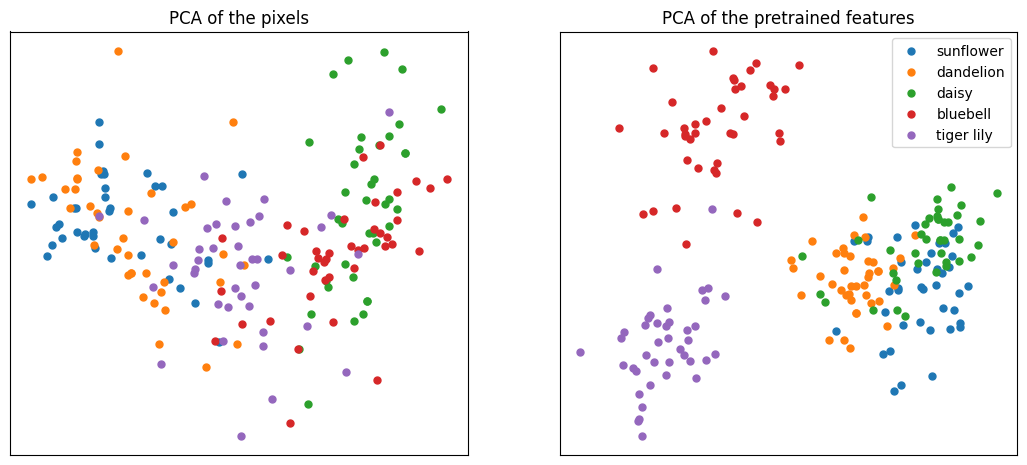

In [13]:
from sklearn.decomposition import PCA

shown = [9, 12, 10, 3, 6]                    # sunflower, dandelion, daisy, bluebell, tiger lily
mask = torch.isin(labels[train_idx], torch.tensor(shown))
fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (name, X) in zip(axs, (('pixels', pixels), ('pretrained features', features))):
    xy = PCA(n_components=2).fit_transform(X[train_idx][mask].numpy())
    for c in shown:
        sel = labels[train_idx][mask].numpy() == c
        ax.scatter(xy[sel, 0], xy[sel, 1], s=25, label=classes[c])
    ax.set_title(f'PCA of the {name}')
    ax.set_xticks([]); ax.set_yticks([])
axs[1].legend(loc='best')
plt.show()

## Strategy 1: Feature Extraction

Now the lecture's four steps: load the pretrained network, **freeze** it, **replace** its head, and train only the new head.

**Step 1 and 2: load and freeze.** Setting `requires_grad = False` on a parameter tells autograd not to compute its gradient, so the optimizer cannot change it.

In [14]:
model = models.resnet18(weights=weights)
print(f'all parameters: {sum(p.numel() for p in model.parameters()):,d}')
print(f'trainable before freezing: {trainable(model):,d}')
for param in model.parameters():
    param.requires_grad = False
print(f'trainable after freezing:  {trainable(model):,d}')

all parameters: 11,689,512
trainable before freezing: 11,689,512
trainable after freezing:  0


**Step 3: a new head.** ResNet-18 calls its last layer `fc`: 512 inputs, 1,000 outputs. A new `nn.Linear(512, 17)` replaces it. A new layer has `requires_grad=True`, so it is the only trainable part. The order matters: freezing *after* replacing the head would freeze the new head too, and nothing would learn. (Other networks name the head differently: EfficientNet calls it `classifier`, which is what the parameter tables on the lecture's slides 30 and 31 show.)

In [15]:
print('old head:', model.fc)
torch.manual_seed(0)
model.fc = nn.Linear(model.fc.in_features, len(classes))
print('new head:', model.fc)
print(f'RESULT params_total: {sum(p.numel() for p in model.parameters())}')
print(f'RESULT params_trainable: {trainable(model)}')
model = model.to(device)

old head: Linear(in_features=512, out_features=1000, bias=True)
new head: Linear(in_features=512, out_features=17, bias=True)
RESULT params_total: 11185233
RESULT params_trainable: 8721


**What `backward()` does now.** Run one batch forward and backward and look at the gradients. The head gets one, the frozen layers get none at all (`.grad` stays `None`): no parameter before the head needs a gradient, so autograd does not even go back through them. That is why feature extraction trains so fast.

In [16]:
x = prepare(images[train_idx[:8]])
loss = F.cross_entropy(model(x), labels[train_idx[:8]].to(device))
loss.backward()
print('head gradient:', tuple(model.fc.weight.grad.shape))
print('gradient of the first convolution:', model.conv1.weight.grad)
print('gradient of the last convolution: ', model.layer4[1].conv2.weight.grad)
model.fc.weight.grad = None
model.fc.bias.grad = None

head gradient: (17, 512)
gradient of the first convolution: None
gradient of the last convolution:  None


**Step 4: train.** Only `model.fc.parameters()` go to the optimizer, with `frozen_bn=True` and no augmentation (we will want to compare with cached features below, which are computed from unflipped photos).

In [17]:
start = time.time()
train(model, model.fc.parameters(), train_idx, epochs=5, lr=1e-3, augment=False, frozen_bn=True)
print(f'RESULT fe_test: {accuracy(model, test_idx):.4f}')
print(f'RESULT fe_seconds: {time.time() - start:.0f}')

epoch  1  loss 2.524  validation accuracy 54.7%  (1 s)


epoch  2  loss 1.546  validation accuracy 81.8%  (2 s)


epoch  3  loss 0.995  validation accuracy 87.6%  (2 s)


epoch  4  loss 0.713  validation accuracy 90.0%  (2 s)


epoch  5  loss 0.548  validation accuracy 89.1%  (2 s)


RESULT fe_test: 0.9206
RESULT fe_seconds: 8


### The Same Thing, Much Faster

Because the base never changes, every epoch above pushed the same photos through the same frozen layers and got the same 512 numbers each time. We already have those numbers in `features`. Training a new `nn.Linear(512, 17)` on them directly is the same model, and an epoch takes milliseconds instead of seconds, so we can afford more of them.

In [18]:
torch.manual_seed(0)
head = nn.Linear(512, len(classes))
optimizer = torch.optim.Adam(head.parameters(), lr=1e-3)
generator = torch.Generator().manual_seed(0)
start = time.time()
for epoch in range(30):
    order = train_idx[torch.randperm(len(train_idx), generator=generator)]
    for i in range(0, len(order), 32):
        b = order[i:i + 32]
        loss = F.cross_entropy(head(features[b]), labels[b])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    if epoch + 1 in (5, 10, 20, 30):
        with torch.no_grad():
            val = (head(features[val_idx]).argmax(1) == labels[val_idx]).float().mean().item()
        print(f'epoch {epoch + 1:2d}  validation accuracy {val:.1%}')
with torch.no_grad():
    cached_test = (head(features[test_idx]).argmax(1) == labels[test_idx]).float().mean().item()
print(f'30 epochs in {time.time() - start:.1f} s')
print(f'RESULT fe_cached_test: {cached_test:.4f}')

epoch  5  validation accuracy 89.7%
epoch 10  validation accuracy 92.1%


epoch 20  validation accuracy 94.1%


epoch 30  validation accuracy 94.7%
30 epochs in 0.3 s
RESULT fe_cached_test: 0.9529


## Strategy 2: Fine-Tuning

Fine-tuning lets some of the pretrained layers change too. We unfreeze the last block, `layer4` (8.4 million of the 11.2 million parameters), keep `conv1` to `layer3` frozen, and train it together with a new head. Two details from the lecture:

- a **low learning rate**, 10 times lower than above (`1e-4`), so the pretrained weights are adjusted rather than overwritten;
- a block is unfrozen by setting `requires_grad = True` on its parameters again.

In [19]:
torch.manual_seed(0)
finetuned = models.resnet18(weights=weights)
for param in finetuned.parameters():
    param.requires_grad = False
finetuned.fc = nn.Linear(512, len(classes))
for param in finetuned.layer4.parameters():
    param.requires_grad = True
finetuned = finetuned.to(device)
print(f'trainable parameters: {trainable(finetuned):,d}')
print(f'RESULT params_finetune: {trainable(finetuned)}')

start = time.time()
train(finetuned, [p for p in finetuned.parameters() if p.requires_grad], train_idx, epochs=5, lr=1e-4)
print(f'RESULT ft_test: {accuracy(finetuned, test_idx):.4f}')
print(f'RESULT ft_seconds: {time.time() - start:.0f}')
Path('output').mkdir(exist_ok=True)
torch.save(finetuned.state_dict(), 'output/flowers17_finetuned.pth')

trainable parameters: 8,402,449
RESULT params_finetune: 8402449


epoch  1  loss 1.791  validation accuracy 90.3%  (2 s)


epoch  2  loss 0.439  validation accuracy 92.4%  (2 s)


epoch  3  loss 0.188  validation accuracy 94.7%  (2 s)


epoch  4  loss 0.114  validation accuracy 95.3%  (2 s)


epoch  5  loss 0.067  validation accuracy 96.8%  (2 s)


RESULT ft_test: 0.9618
RESULT ft_seconds: 10


## Results

The same 340 test photos for every method.

1-NN on pixels                           37.6%
from scratch, 10 epochs                  54.4%
1-NN on features                         85.6%
feature extraction, 5 epochs             92.1%
feature extraction, cached, 30 epochs    95.3%
fine-tuning layer4, 5 epochs             96.2%


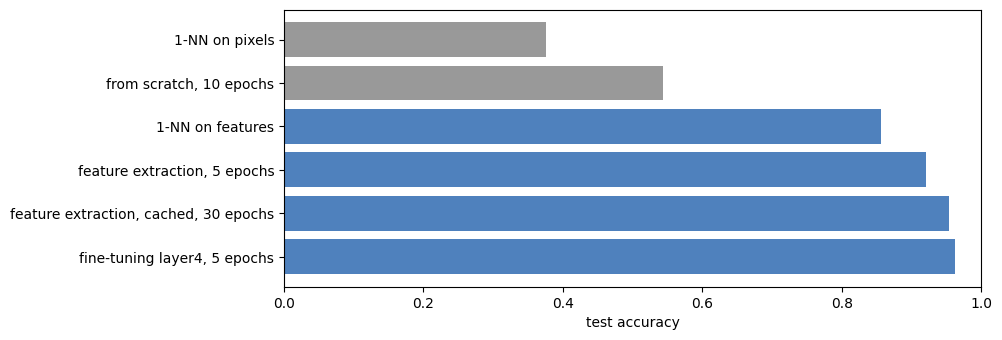

In [20]:
results = {'1-NN on pixels': float(np.mean(KNeighborsClassifier(1).fit(pixels[train_idx], labels[train_idx]).predict(pixels[test_idx]) == labels[test_idx].numpy())),
           'from scratch, 10 epochs': accuracy(scratch, test_idx),
           '1-NN on features': float(np.mean(KNeighborsClassifier(1).fit(features[train_idx], labels[train_idx]).predict(features[test_idx]) == labels[test_idx].numpy())),
           'feature extraction, 5 epochs': accuracy(model, test_idx),
           'feature extraction, cached, 30 epochs': cached_test,
           'fine-tuning layer4, 5 epochs': accuracy(finetuned, test_idx)}
for name, acc in results.items():
    print(f'{name:40s} {acc:.1%}')
plt.figure(figsize=(9, 3.6))
plt.barh(list(results), list(results.values()), color=['#999999', '#999999', '#4F81BD', '#4F81BD', '#4F81BD', '#4F81BD'])
plt.xlim(0, 1); plt.xlabel('test accuracy'); plt.gca().invert_yaxis()
plt.show()

### Which Flowers Does It Still Get Wrong?

13 of 340 test photos wrong


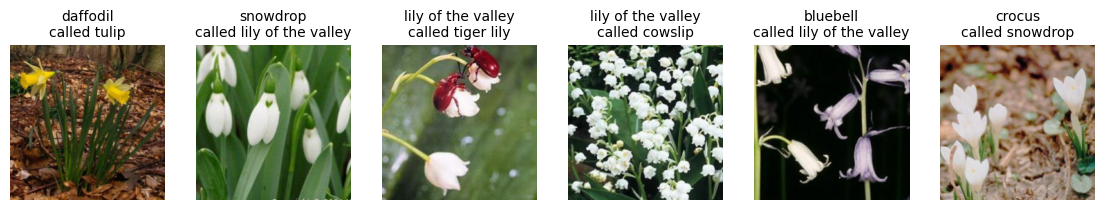

In [21]:
finetuned.eval()
with torch.no_grad():
    predicted = torch.cat([finetuned(prepare(images[test_idx[i:i + 100]])).argmax(1).cpu() for i in range(0, len(test_idx), 100)])
wrong = test_idx[predicted != labels[test_idx]]
print(len(wrong), 'of', len(test_idx), 'test photos wrong')
fig, axs = plt.subplots(1, min(len(wrong), 6), figsize=(14, 3.4), squeeze=False)
for ax, i in zip(axs[0], wrong):
    ax.imshow(images[i].permute(1, 2, 0))
    ax.set_title(f'{classes[labels[i]]}\ncalled {classes[predicted[test_idx == i].item()]}', fontsize=10)
    ax.axis('off')
plt.show()

## How Much Data Do You Need?

The cached features make this cheap to measure: train the head on 5, 10, 20 and all 40 training photos per class (the same photos each time, the first ones of the split) and test on the same 340 test photos. The 1-nearest-neighbor classifier on features is shown too. (Fine-tuning and training from scratch need a GPU for such a sweep; the lecture's "how many photos" slide shows them.)

In [22]:
def head_on_features(idx, epochs=30):
    torch.manual_seed(0)
    h = nn.Linear(512, len(classes))
    opt = torch.optim.Adam(h.parameters(), lr=1e-3)
    gen = torch.Generator().manual_seed(0)
    steps = epochs * len(train_idx) // 32                  # the same number of updates for every size
    for step in range(steps):
        b = idx[torch.randint(len(idx), (32,), generator=gen)]
        loss = F.cross_entropy(h(features[b]), labels[b])
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        return (h(features[test_idx]).argmax(1) == labels[test_idx]).float().mean().item()

for n in (5, 10, 20, 40):
    subset = torch.cat([train_idx[labels[train_idx] == c][:n] for c in range(len(classes))])
    knn = KNeighborsClassifier(1).fit(features[subset], labels[subset])
    knn_acc = (knn.predict(features[test_idx]) == labels[test_idx].numpy()).mean()
    print(f'{n:2d} photos per class ({len(subset):3d} in all):  head on features {head_on_features(subset):.1%}   1-NN on features {knn_acc:.1%}')

 5 photos per class ( 85 in all):  head on features 87.1%   1-NN on features 73.8%


10 photos per class (170 in all):  head on features 88.8%   1-NN on features 78.5%


20 photos per class (340 in all):  head on features 90.6%   1-NN on features 84.4%


40 photos per class (680 in all):  head on features 94.7%   1-NN on features 85.6%


## Your Inputs Must Match

The fine-tuned network was trained on photos prepared exactly as `weights.transforms()` says. Here is what happens to its test accuracy when one step is done differently, the kind of slip that happens when you write the preprocessing yourself:

- **no normalization**: values 0 to 1, without subtracting the ImageNet mean and dividing by the standard deviation;
- **BGR order**: the photo loaded with `cv.imread`, which gives blue, green, red, and passed on without `cv.cvtColor`;
- **stretched**: resized straight to 224 × 224, which squashes the flower, instead of resizing the short side and cropping the center.

In [23]:
stretch = transforms.Compose([transforms.Resize((224, 224)), transforms.PILToTensor()])
stretched = torch.stack([stretch(Image.open(files[i]).convert('RGB')) for i in test_idx])

def test_accuracy(x_float):
    """x_float: (340, 3, 224, 224) inputs ready for the network, in test_idx order."""
    finetuned.eval()
    with torch.no_grad():
        out = torch.cat([finetuned(x_float[i:i + 100].to(device)).argmax(1).cpu() for i in range(0, len(x_float), 100)])
    return (out == labels[test_idx]).float().mean().item()

crops = images[test_idx]
variants = {'correct': (crops.float() / 255 - mean) / std,
            'no normalization': crops.float() / 255,
            'BGR order': (crops.flip(1).float() / 255 - mean) / std,
            'stretched': (stretched.float() / 255 - mean) / std}
for name, x in variants.items():
    acc = test_accuracy(x)
    print(f'{name:18s} {acc:.1%}')
    print(f'RESULT input_{name.split()[0].lower()}: {acc:.4f}')

correct            96.2%
RESULT input_correct: 0.9618


no normalization   81.5%
RESULT input_no: 0.8147


BGR order          82.6%
RESULT input_bgr: 0.8265


stretched          95.3%
RESULT input_stretched: 0.9529


Stretching costs little here only because most photos in this dataset are close to square (about 500 × 540 pixels), so squashing them to 224 × 224 hardly changes their shape; on a wide phone photo it distorts much more. The other two mistakes change every pixel the network sees.

Two test photos loaded the OpenCV way, with and without the conversion to RGB. Each is shown the way the network receives it: without the conversion, red and blue trade places, a blue bluebell turns red and an orange tiger lily turns blue. Converting to RGB is the one line that matters.

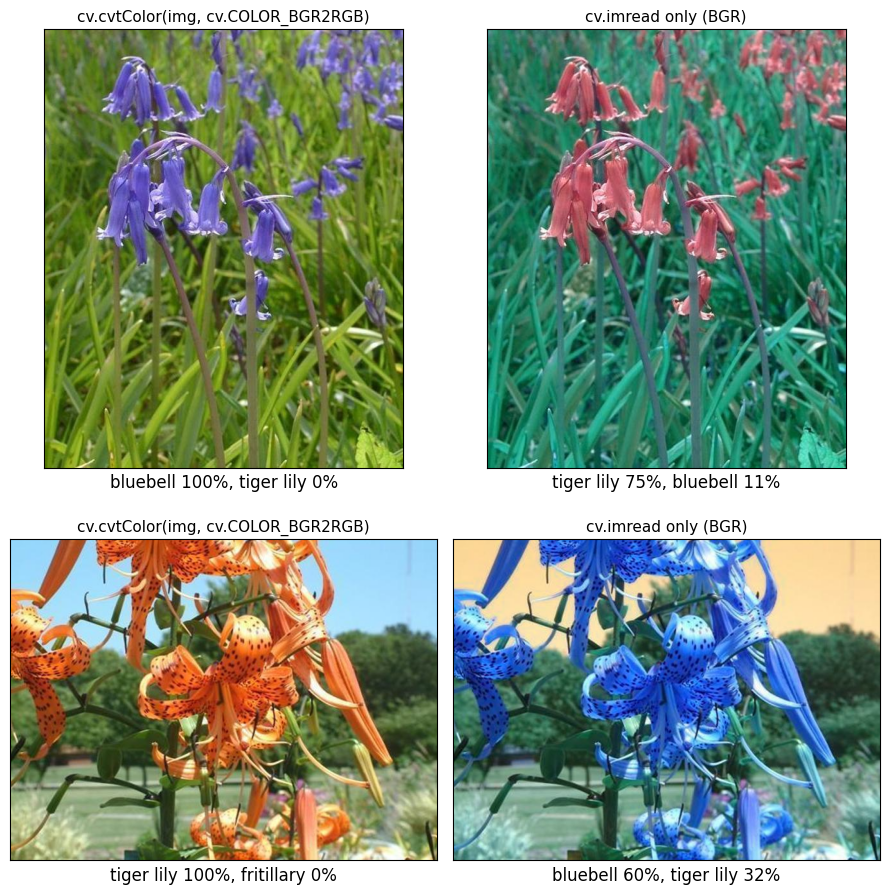

In [24]:
to_input = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.ToTensor(),
                               transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
fig, axs = plt.subplots(2, 2, figsize=(9, 9.4))
for row, i in enumerate((283, 530)):                    # a bluebell and a tiger lily from the test set
    bgr = cv.imread(str(files[i]))
    for ax, (name, array) in zip(axs[row], (('cv.cvtColor(img, cv.COLOR_BGR2RGB)', cv.cvtColor(bgr, cv.COLOR_BGR2RGB)), ('cv.imread only (BGR)', bgr))):
        x = to_input(Image.fromarray(array))[None].to(device)
        with torch.no_grad():
            p = F.softmax(finetuned(x), dim=1)[0].cpu()
        top = p.topk(2)
        ax.imshow(array)
        ax.set_title(name, fontsize=11)
        ax.set_xlabel(', '.join(f'{classes[k]} {v:.0%}' for v, k in zip(top.values, top.indices)), fontsize=12)
        ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

## Try It Yourself

1. Fine-tune with `lr=1e-2` instead of `1e-4`, and with all layers unfrozen. What happens to the validation accuracy in the first epochs, and why does the lecture insist on a low learning rate?
2. Train the from-scratch network for 30 epochs (on a GPU, or overnight). How close does it get to feature extraction?
3. Use `models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)` instead. Its head is `model.classifier`, a `Sequential` whose last layer is `nn.Linear(1280, 1000)`. What do you have to change, and is it better than ResNet-18?
4. Use the cosine distance for the nearest neighbors (normalize the feature vectors to length 1 first, with `F.normalize`). Does the accuracy change?
5. Unfreeze `layer3` as well. Does the accuracy change? How many parameters are now trainable?
6. Photograph a few flowers (or other objects of a few kinds) yourself and classify them with `finetuned` or with a head trained on your own photos. This is the starting point of most final projects: how does accuracy on your own photos compare with accuracy on the test set?